# 01 - Look at the data and make two splits

**Goal of this notebook:** no model yet. We only (1) look at the skin photos and (2) split them
in two ways, a *naive* way and a *fair* way. Then we count how many test photos the naive split
"leaks" from training. That number is your first finding.

**Not a medical tool.** This is a learning/research project about how models get fooled.

## Step 0 - Get the data (once)
Download **HAM10000** from Kaggle: https://www.kaggle.com/datasets/kmader/skin-cancer-mnist-ham10000  
Easiest way: click *Download*, unzip into `data/` so you have `data/HAM10000_metadata.csv` and the two image folders `data/HAM10000_images_part_1` and `data/HAM10000_images_part_2`.

(Or with the Kaggle CLI: `kaggle datasets download -d kmader/skin-cancer-mnist-ham10000 -p data --unzip`)

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split, GroupShuffleSplit

DATA = Path("data/archive-5")
SEED = 42  # same seed = same split every time you run
meta = pd.read_csv(DATA / "HAM10000_metadata.csv")
meta.head()

,lesion_id,image_id,dx,dx_type,age,sex,localization
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear


## Step 1 - What is in the table?
- `image_id`: one photo
- `lesion_id`: one **spot on a person**. Several photos can share the same `lesion_id`
- `dx`: the diagnosis (the answer the model must learn): `nv` harmless mole, `mel` melanoma, `bkl`, `bcc`, `akiec`, `vasc`, `df`

In [2]:
print("photos:", len(meta))
print("distinct spots (lesion_id):", meta.lesion_id.nunique())
print()
counts = meta.dx.value_counts()
print(counts)
print()
print(f"Majority-class baseline: always answering 'nv' is right {counts.max()/len(meta):.1%} of the time")

photos: 10015
distinct spots (lesion_id): 7470

dx
nv       6705
mel      1113
bkl      1099
bcc       514
akiec     327
vasc      142
df        115
Name: count, dtype: int64

Majority-class baseline: always answering 'nv' is right 66.9% of the time


**Remember that last number.** A model that learned nothing and just says "harmless mole" gets about 67%. Any score has to be judged against it.

## Step 2 - How many photos does each spot have?

In [3]:
per_lesion = meta.groupby("lesion_id").size()
print(per_lesion.value_counts().sort_index())
print()
multi = (per_lesion > 1).sum()
print(f"{multi} spots ({multi/len(per_lesion):.1%}) have more than one photo")
print(f"{per_lesion[per_lesion > 1].sum()} photos ({per_lesion[per_lesion > 1].sum()/len(meta):.1%}) belong to those spots")

1    5514
2    1423
3     490
4      34
5       5
6       4
Name: count, dtype: int64

1956 spots (26.2%) have more than one photo
4501 photos (44.9%) belong to those spots


## Step 3 - Look at some photos

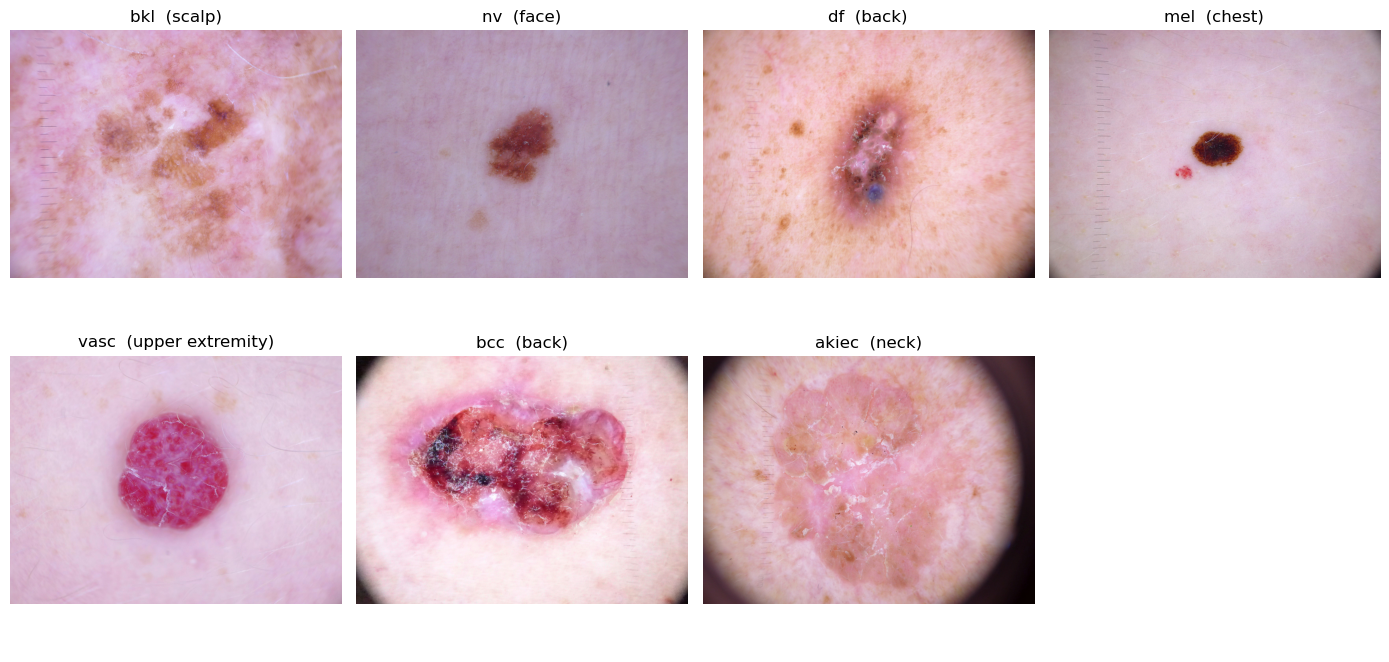

In [4]:
def find_image(image_id):
    for part in ("HAM10000_images_part_1", "HAM10000_images_part_2"):
        p = DATA / part / f"{image_id}.jpg"
        if p.exists():
            return p
    raise FileNotFoundError(image_id)

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, (_, row) in zip(axes.flat, meta.groupby("dx").head(1).head(7).iterrows()):
    ax.imshow(Image.open(find_image(row.image_id)))
    ax.set_title(f"{row.dx}  ({row.localization})")
    ax.axis("off")
axes.flat[-1].axis("off")
plt.tight_layout(); plt.show()

Now look at a spot with several photos. Same spot, slightly different pictures:

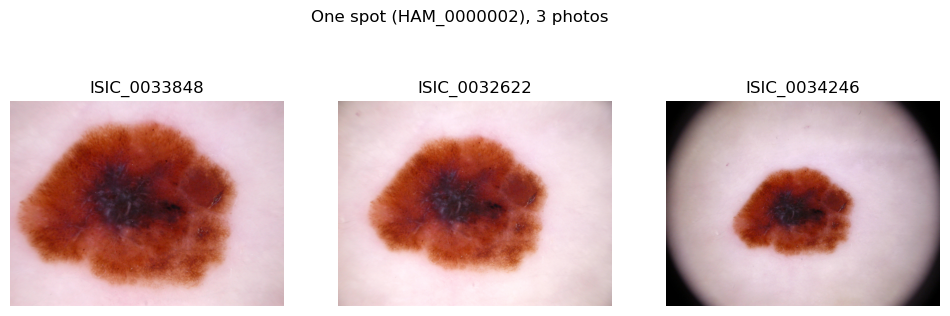

In [5]:
spot = per_lesion[per_lesion >= 3].index[0]
rows = meta[meta.lesion_id == spot]
fig, axes = plt.subplots(1, len(rows), figsize=(4 * len(rows), 4))
for ax, (_, row) in zip(axes, rows.iterrows()):
    ax.imshow(Image.open(find_image(row.image_id))); ax.axis("off"); ax.set_title(row.image_id)
plt.suptitle(f"One spot ({spot}), {len(rows)} photos"); plt.show()

## Step 4 - The naive split (this is the "cheating-prone" way)
Shuffle all photos and put 80% in training, 20% in the test set. Sounds fine, but photos of the
same spot can land on both sides.

In [6]:
naive_train, naive_test = train_test_split(meta, test_size=0.2, random_state=SEED, stratify=meta.dx)

## Step 5 - The fair split
Keep **all photos of one spot on the same side**. `GroupShuffleSplit` does exactly that when you
tell it which column is the group (`lesion_id`).

In [7]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
train_idx, test_idx = next(gss.split(meta, groups=meta.lesion_id))
fair_train, fair_test = meta.iloc[train_idx], meta.iloc[test_idx]

## Step 6 - Your first finding: how many test photos were already seen?

In [8]:
def leaked(train, test):
    return test.lesion_id.isin(set(train.lesion_id))

for name, tr, te in [("naive", naive_train, naive_test), ("fair", fair_train, fair_test)]:
    n = leaked(tr, te).sum()
    print(f"{name:5s}: {n:4d} of {len(te)} test photos ({n/len(te):.1%}) show a spot that is also in training")

naive:  791 of 2003 test photos (39.5%) show a spot that is also in training
fair :    0 of 2024 test photos (0.0%) show a spot that is also in training


The naive split should show a clear percentage. The fair split must show **0**. If the fair split
is not 0, something is wrong. The `assert` below checks it for you.

In [9]:
assert leaked(fair_train, fair_test).sum() == 0, "fair split leaks!"
print("fair split is clean")

fair split is clean


## Step 7 - Check the two test sets are comparable
Both test sets should have a similar mix of diagnoses, otherwise the later comparison is unfair.

In [10]:
pd.DataFrame({
    "naive_test": naive_test.dx.value_counts(normalize=True),
    "fair_test": fair_test.dx.value_counts(normalize=True),
}).round(3)

,naive_test,fair_test
dx,,
akiec,0.032,0.033
bcc,0.051,0.044
bkl,0.110,0.120
df,0.011,0.009
mel,0.111,0.117
nv,0.669,0.660
vasc,0.014,0.017


## Step 8 - Save the splits
Next notebook loads these so both models use exactly the same photos.

In [11]:
Path("splits").mkdir(exist_ok=True)
naive_train.to_csv("splits/naive_train.csv", index=False); naive_test.to_csv("splits/naive_test.csv", index=False)
fair_train.to_csv("splits/fair_train.csv", index=False);   fair_test.to_csv("splits/fair_test.csv", index=False)
print("saved to splits/")

saved to splits/


### Write down for your README
- Photos / distinct spots: ____ / ____
- Majority-class baseline: ____%
- Naive split leaks: ____% of test photos
- Fair split leaks: 0

**Next (notebook 02):** train the same model on each split and compare the scores.